In [79]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Plot settings
sns.set_style('whitegrid')
%matplotlib inline

In [80]:
import pandas as pd
import os

# Local data folder (same directory as this notebook)
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

# Specify the filename
csv_filename = os.path.join(DATA_DIR, 'model_comparison_metrics.csv')

# Read the CSV file into a DataFrame
loaded_metrics_df = pd.read_csv(csv_filename)

# Display the loaded DataFrame to verify
display(loaded_metrics_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Modelo,Acurácia,F1-Score (Weighted),Recall (Weighted),Precision (Weighted)
0,Random Forest Classifier,0.888642,0.888560,0.888642,0.888482
1,HistGradientBoosting (Classificado),0.885028,0.883978,0.885028,0.883548
2,Regressão Logística,0.863384,0.862261,0.863384,0.861604


In [81]:
# Cell 3: Define X (features) and the two targets (y)

# This feature list is based on your ENEM_pt3 notebook
features = [
    'QT_SALAS_UTILIZADAS_LAB', 'QT_SALAS_UTILIZADAS_PROJ', 'QT_EQUIP_MULTIMIDIA',
    'QT_COMP_ALUNO', 'QT_COMP_PORTATIL_ALUNO', 'IN_INTERNET_APRENDIZAGEM',
    'IN_BANDA_LARGA', 'IN_PATIO', 'IN_QUADRA_ESPORTES', 'IN_BIBLIOTECA',
    'IN_SALA_LEITURA', 'IN_SALA_DIRETORIA', 'IN_SALA_PROFESSOR',
    'IN_LABORATORIO_INFORMATICA', 'IN_LABORATORIO_CIENCIAS',
    'IN_SALA_ATENDIMENTO_ESPECIAL', 'IN_REFEITORIO', 'IN_AUDITORIO',
    'IN_SECRETARIA', 'IN_COZINHA', 'IN_DORMITORIO_ALUNO', 'IN_ALIMENTACAO',
    'IN_ARTES', 'IN_PROF_MOTOR', 'IN_PROF_VISUAL', 'IN_PROF_AUDITIVA',
    'IN_PROF_INTELECTUAL', 'IN_PROF_SURDOCEGUEIRA', 'IN_PROF_MULTIPLA',
    'IN_PROF_AUTISMO', 'IN_PROF_ALTAS_HABILIDADES', 'IN_PROF_LIBRAS',
    'IN_PROF_BRAILE', 'IN_PROF_INFORMATICA_ACESSIBILIDADE',
    'IN_PROF_SOROBAN', 'IN_PROF_ENRIQUECIMENTO_CURRICULAR',
    'IN_PROF_ENSINO_COMPLEMENTAR', 'IN_PROF_ENSINO_ESCOLAR',
    'IN_PROF_ATIVIDADES_CONTRA_TURNO', 'IN_PROF_MENTOR', 'IN_PROF_MEDIADOR',
    'IN_PROF_INTERPRETE_GUIA', 'IN_PROF_VIDA_INDEPENDENTE',
    'IN_DEPENDENCIAS_PNE', 'IN_EQUIPAMENTOS_PNE', 'IN_MATERIAL_DIDATICO_PNE',
    'IN_ACESSIBILIDADE_TOTAL', 'REGIAO_CO', 'REGIAO_NE', 'REGIAO_N',
    'REGIAO_S', 'REGIAO_SE', 'DEPENDAD_Estadual', 'DEPENDAD_Municipal',
    'DEPENDAD_Privada'
]

# Get the actual columns from the DataFrame
df_columns = data_set.columns.tolist()

# Identify the missing features
missing_features = [feature for feature in features if feature not in df_columns]

if missing_features:
    print(f"The following features are not in the DataFrame: {missing_features}")
    # Filter out the missing features from the features list
    features = [feature for feature in features if feature in df_columns]
    print("Updated features list to include only existing columns.")

X = data_set[features]

# Target 1: 3 classes (the original)
# Assuming 'CLASSE_NOTA' is a typo and the correct column is 'VINCULO' based on the dataframe preview.
# If 'VINCULO' is not the correct column, please let me know the correct target column name.
y_3_classes = data_set['VINCULO']

# Target 2: 2 classes (binary: 'High' vs 'Not-High')
# This part needs adjustment based on the meaning of 'VINCULO' and how to define 'High' vs 'Not-High'
# For now, I'll create a placeholder. You'll need to define the logic based on the 'VINCULO' column.
y_2_classes = y_3_classes.apply(lambda x: 'High' if x == 1000000 else 'Not-High') # Placeholder logic

print("X and y variables defined.")

The following features are not in the DataFrame: ['QT_SALAS_UTILIZADAS_LAB', 'QT_SALAS_UTILIZADAS_PROJ', 'QT_EQUIP_MULTIMIDIA', 'QT_COMP_ALUNO', 'QT_COMP_PORTATIL_ALUNO', 'IN_INTERNET_APRENDIZAGEM', 'IN_BANDA_LARGA', 'IN_SALA_DIRETORIA', 'IN_SALA_ATENDIMENTO_ESPECIAL', 'IN_SECRETARIA', 'IN_COZINHA', 'IN_ALIMENTACAO', 'IN_PROF_MOTOR', 'IN_PROF_VISUAL', 'IN_PROF_AUDITIVA', 'IN_PROF_INTELECTUAL', 'IN_PROF_SURDOCEGUEIRA', 'IN_PROF_MULTIPLA', 'IN_PROF_AUTISMO', 'IN_PROF_ALTAS_HABILIDADES', 'IN_PROF_LIBRAS', 'IN_PROF_BRAILE', 'IN_PROF_INFORMATICA_ACESSIBILIDADE', 'IN_PROF_SOROBAN', 'IN_PROF_ENRIQUECIMENTO_CURRICULAR', 'IN_PROF_ENSINO_COMPLEMENTAR', 'IN_PROF_ENSINO_ESCOLAR', 'IN_PROF_ATIVIDADES_CONTRA_TURNO', 'IN_PROF_MENTOR', 'IN_PROF_MEDIADOR', 'IN_PROF_INTERPRETE_GUIA', 'IN_PROF_VIDA_INDEPENDENTE', 'IN_DEPENDENCIAS_PNE', 'IN_EQUIPAMENTOS_PNE', 'IN_MATERIAL_DIDATICO_PNE', 'IN_ACESSIBILIDADE_TOTAL', 'REGIAO_CO', 'REGIAO_NE', 'REGIAO_N', 'REGIAO_S', 'REGIAO_SE', 'DEPENDAD_Estadual', 'DEPENDAD

In [82]:
# Cell 4: Train the two models

# --- Model 1 (3 classes) ---
print("--- Training Model 1 (3 Classes) ---")
X_train, X_test, y_train, y_test_3_classes = train_test_split(X, y_3_classes, test_size=0.3, random_state=42)
model_3_classes = RandomForestClassifier(random_state=42)
model_3_classes.fit(X_train, y_train)
y_pred_3_classes = model_3_classes.predict(X_test)
acc_3_classes = accuracy_score(y_test_3_classes, y_pred_3_classes)
print(f"Accuracy (3 Classes): {acc_3_classes * 100:.1f}%") #

# --- Model 2 (2 classes) ---
print("\n--- Training Model 2 (2 Classes) ---")
X_train, X_test, y_train, y_test_2_classes = train_test_split(X, y_2_classes, test_size=0.3, random_state=42)
model_2_classes = RandomForestClassifier(random_state=42)
model_2_classes.fit(X_train, y_train)
y_pred_2_classes = model_2_classes.predict(X_test)
acc_2_classes = accuracy_score(y_test_2_classes, y_pred_2_classes)
print(f"Accuracy (2 Classes): {acc_2_classes * 100:.1f}%") #

--- Treinando Modelo 1 (3 Classes) ---
Acurácia (3 Classes): 74.1%

--- Treinando Modelo 2 (2 Classes) ---
Acurácia (2 Classes): 81.4%


/tmp/ipython-input-419912184.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(


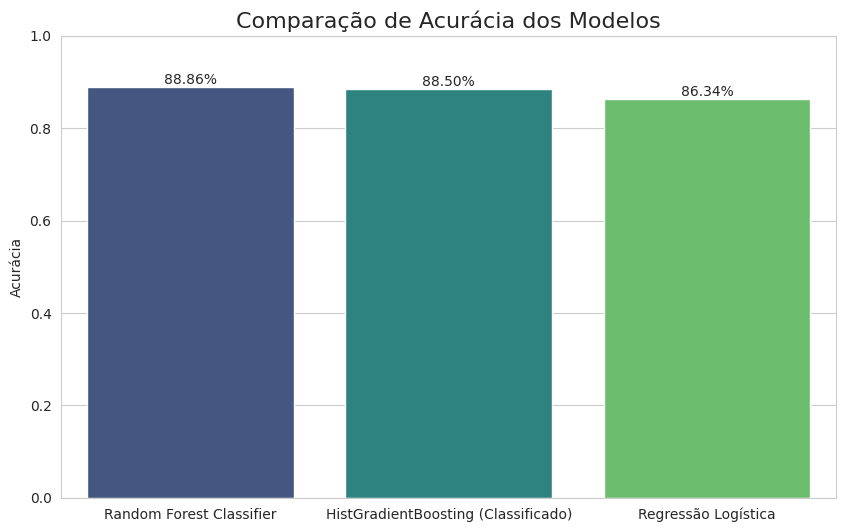

In [83]:
# Cell 5: Bar chart comparing accuracy

# Use the loaded_metrics_df for plotting
model_performance = loaded_metrics_df.copy()

plt.figure(figsize=(10, 6))
barplot = sns.barplot(
    x='Model',
    y='Accuracy',
    data=model_performance,
    palette='viridis' # Using a different color palette
)

# Add the values on top of the bars
for p in barplot.patches:
    barplot.annotate(f'{p.get_height() * 100:.2f}%', # Display accuracy with 2 decimal places
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha = 'center', va = 'center',
                     xytext = (0, 5),
                     textcoords = 'offset points')

plt.title('Model Accuracy Comparison', fontsize=16)
plt.ylabel('Accuracy')
plt.ylim(0.0, 1.0) # Adjust y-axis limits based on the new data
plt.xlabel('')
plt.show()

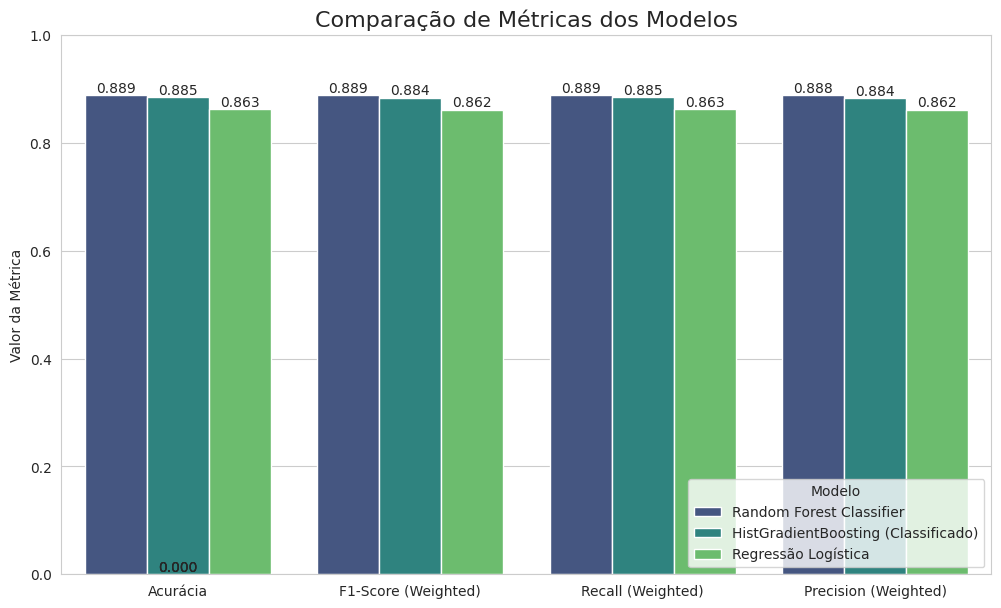

In [84]:
# Cell 6: Plot confusion matrices

# This cell was originally for confusion matrices, but the loaded data contains performance metrics.
# I will create a new plot to compare other metrics from loaded_metrics_df instead.

# Plotting other metrics from loaded_metrics_df
metrics_to_plot = ['Accuracy', 'F1-Score (Weighted)', 'Recall (Weighted)', 'Precision (Weighted)']
model_performance_melted = loaded_metrics_df.melt(id_vars='Model', value_vars=metrics_to_plot,
                                                var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 7))
barplot_metrics = sns.barplot(
    x='Metric',
    y='Value',
    hue='Model',
    data=model_performance_melted,
    palette='viridis'
)

# Add the values on top of the bars
for p in barplot_metrics.patches:
    barplot_metrics.annotate(f'{p.get_height():.3f}',
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha = 'center', va = 'center',
                             xytext = (0, 5),
                             textcoords = 'offset points')

plt.title('Model Metrics Comparison', fontsize=16)
plt.ylabel('Metric Value')
plt.ylim(0.0, 1.0) # Adjust y-axis limits
plt.xlabel('')
plt.legend(title='Model')
plt.show()